# Lab 4 of 8 — Unsupervised learning I: clustering and PCA

*Find structure without an answer key.*

**Coverage.** Chapters 15–17.

**Goal.** Choose K from evidence, compare DBSCAN, and evaluate PCA through reconstruction and downstream accuracy.

## Setup

In [1]:
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def find_data_dir(name="all_datasets", marker="mall_customers_dataset.csv"):
    """Search the script/working folder and their parents for a data folder holding `marker`."""
    starts = [Path.cwd()]
    try:
        starts.insert(0, Path(__file__).resolve().parent)  # not defined inside a notebook
    except NameError:
        pass
    for start in starts:
        for folder in [start, *start.parents]:
            if (folder / name / marker).is_file():
                return folder / name
    raise FileNotFoundError(f"Could not find {name}/{marker} above {starts}")


# The PDF's `PROJECT_ROOT = Path.cwd().parent` only works for notebooks directly in all_experiments/;
# this finds the same project root from inside "ML Lab 4/".
DATA = find_data_dir()
PROJECT_ROOT = DATA.parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A — How many clusters? Elbow and silhouette

Standardize age, income, and spending score for 200 mall customers; investigate useful segments without labels.

In [2]:
customers = pd.read_csv(DATA / "mall_customers_dataset.csv")
print(customers.head())
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(customers[features])

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


Try K = 2–8. Inertia measures within-cluster squared distances and falls with K; silhouette measures cohesion versus separation.

k=2  inertia=389.4  silhouette=0.335
k=3  inertia=295.2  silhouette=0.358
k=4  inertia=205.2  silhouette=0.404
k=5  inertia=168.2  silhouette=0.417


k=6  inertia=133.9  silhouette=0.427
k=7  inertia=117.0  silhouette=0.417
k=8  inertia=103.8  silhouette=0.409


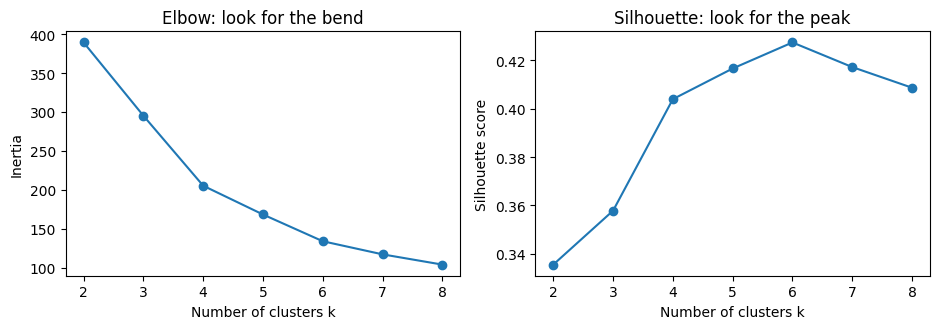

In [3]:
ks, inertias, silhouettes = [], [], []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(X)
    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))
    print(f"k={k}  inertia={kmeans.inertia_:.1f}  silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: look for the bend")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: look for the peak")
plt.tight_layout()
plt.show()

**Inspect.** Inertia keeps falling with K and bends around K = 4–6 (389 → 295 → 205 → 168 → 134 → 117), while silhouette rises to a peak at K = 6 (0.427), narrowly ahead of K = 5 (0.417) and K = 7 (0.417). Both plots therefore point to five or six groups, but the gap between them is tiny, so the score cannot decide alone — domain usefulness must guide the choice.

## Part B — K-means versus DBSCAN

K-means assigns every customer. DBSCAN uses radius and neighbor count, leaving noise labeled −1.

In [4]:
kmeans = KMeans(n_clusters=5, n_init=30, random_state=42)
k_labels = kmeans.fit_predict(X)
print("K-means silhouette:", round(silhouette_score(X, k_labels), 3))

dbscan = DBSCAN(eps=0.75, min_samples=6)
d_labels = dbscan.fit_predict(X)
is_clustered = d_labels != -1
n_clusters = len(set(d_labels[is_clustered]))
print("DBSCAN clusters:", n_clusters, " noise points:", int((~is_clustered).sum()))
if n_clusters >= 2:
    print("DBSCAN silhouette (clustered points only):",
          round(silhouette_score(X[is_clustered], d_labels[is_clustered]), 3))

K-means silhouette: 0.417
DBSCAN clusters: 1  noise points: 14


Describe clusters using means of the original features.

In [5]:
segments = customers.copy()
segments["kmeans_cluster"] = k_labels
segments["dbscan_cluster"] = d_labels
profile = segments.groupby("kmeans_cluster")[features].mean().round(1)
profile["customers"] = segments["kmeans_cluster"].value_counts().sort_index()
print(profile)

                 Age  Annual Income (k$)  Spending Score (1-100)  customers
kmeans_cluster                                                             
0               46.2                26.8                    18.4         20
1               25.2                41.1                    62.2         54
2               32.9                86.1                    81.5         40
3               39.9                86.1                    19.4         39
4               55.6                54.4                    48.9         47


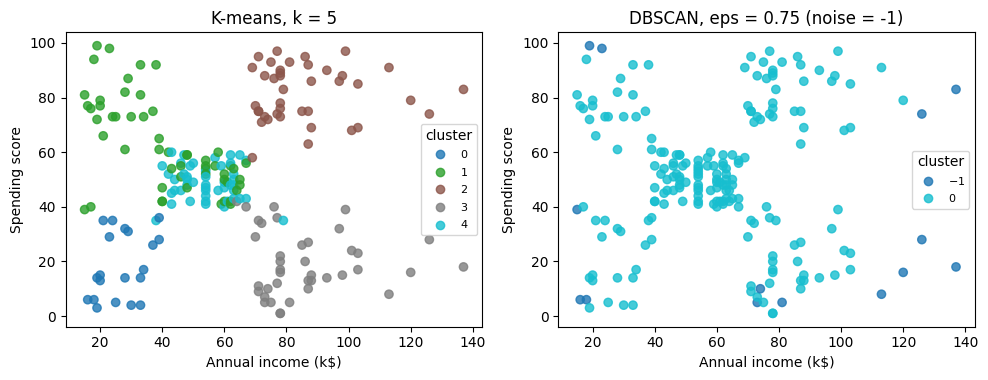

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
panels = [(axes[0], k_labels, "K-means, k = 5"),
          (axes[1], d_labels, "DBSCAN, eps = 0.75 (noise = -1)")]
for ax, labels, title in panels:
    scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                         c=labels, cmap="tab10", alpha=0.8)
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

**Inspect.** K-means partitions the income/spending plane into five segments (low income/low spend, low income/high spend, mid/mid, high income/high spend, high income/low spend) and assigns every customer. DBSCAN at eps = 0.75 merges almost everything into one dense cloud and marks 14 customers as noise, because it looks for density-connected regions rather than compact blobs, and the five K-means groups touch each other with no empty gap between them. Different grouping assumptions explain the contrast; a smaller eps (see *Try it yourself*) splits the cloud.

## Part C — PCA as compression, judged by a downstream model

Each digit has 8 × 8 = 64 pixels. Use the official training split; reserve test evaluation until the final comparison.

In [7]:
archive_path = DATA / "optical_recognition_handwritten_digits.zip"
columns = [f"pixel_{i}" for i in range(64)] + ["label"]
with zipfile.ZipFile(archive_path) as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

X_dev = train.drop(columns="label") / 16.0  # pixel values 0-16 -> 0-1
y_dev = train["label"]
X_test = test.drop(columns="label") / 16.0
y_test = test["label"]
print("training digits:", len(X_dev), " test digits:", len(X_test))

training digits: 3823  test digits: 1797


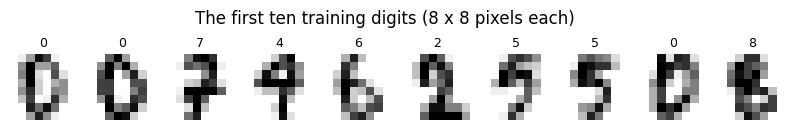

In [8]:
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, (_, row), label in zip(axes, X_dev.head(10).iterrows(), y_dev.head(10)):
    ax.imshow(row.to_numpy().reshape(8, 8), cmap="gray_r")
    ax.set_title(str(label), fontsize=9)
    ax.axis("off")
plt.suptitle("The first ten training digits (8 x 8 pixels each)", y=1.05)
plt.show()

Validate PCA budgets retaining 90%, 95%, or 99% variance through classifier accuracy on training-file holdouts.

In [9]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)
baseline = LogisticRegression(max_iter=2000).fit(X_fit, y_fit)
print("all 64 pixels: validation accuracy =",
      round(accuracy_score(y_valid, baseline.predict(X_valid)), 4))

for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        ("pca", PCA(n_components=retained_variance, svd_solver="full")),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    candidate.fit(X_fit, y_fit)
    n_kept = candidate.named_steps["pca"].n_components_
    print(f"{retained_variance:.0%} variance: {n_kept:2d} components, "
          f"validation accuracy = {accuracy_score(y_valid, candidate.predict(X_valid)):.4f}")

all 64 pixels: validation accuracy = 0.955
90% variance: 21 components, validation accuracy = 0.9487
95% variance: 29 components, validation accuracy = 0.9540


99% variance: 41 components, validation accuracy = 0.9561


Lock 95%, refit both PCA and full-pixel pipelines on all training rows, then compare once on the official test file.

In [10]:
final_model = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("model", LogisticRegression(max_iter=2000)),
])
final_model.fit(X_dev, y_dev)
full_model = LogisticRegression(max_iter=2000).fit(X_dev, y_dev)
pca = final_model.named_steps["pca"]

print("\nFINAL TEST (official test file)")
print("all 64 pixels accuracy:", round(accuracy_score(y_test, full_model.predict(X_test)), 4))
print("PCA components kept:", pca.n_components_,
      " variance retained:", round(pca.explained_variance_ratio_.sum(), 4))
print("PCA -> logistic accuracy:", round(accuracy_score(y_test, final_model.predict(X_test)), 4))


FINAL TEST (official test file)
all 64 pixels accuracy: 0.9477
PCA components kept: 29  variance retained: 0.9537
PCA -> logistic accuracy: 0.9477


Reconstruct test digits from component scores and inspect cumulative explained variance.

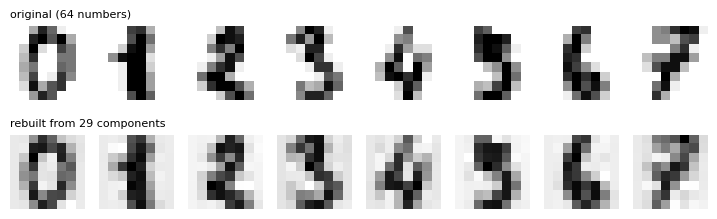

In [11]:
reconstructed = pca.inverse_transform(pca.transform(X_test.head(8)))
fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for j in range(8):
    axes[0, j].imshow(X_test.iloc[j].to_numpy().reshape(8, 8), cmap="gray_r")
    axes[1, j].imshow(reconstructed[j].reshape(8, 8), cmap="gray_r")
    axes[0, j].axis("off")
    axes[1, j].axis("off")
axes[0, 0].set_title("original (64 numbers)", fontsize=8, loc="left")
axes[1, 0].set_title(f"rebuilt from {pca.n_components_} components", fontsize=8, loc="left")
plt.show()

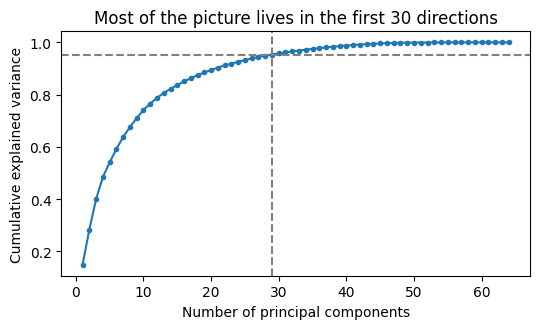

In [12]:
plt.figure(figsize=(5.5, 3.4))
all_components = PCA(svd_solver="full").fit(X_dev)
plt.plot(np.arange(1, 65), np.cumsum(all_components.explained_variance_ratio_), marker=".")
plt.axhline(0.95, linestyle="--", color="grey")
plt.axvline(pca.n_components_, linestyle="--", color="grey")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Most of the picture lives in the first 30 directions")
plt.tight_layout()
plt.show()

**Inspect.** Reconstructions blur slightly while accuracy holds: 29 components (95% of variance) reproduce the digits recognisably, and on the official test file the PCA pipeline scores the same as the full 64-pixel model (0.9477 both). The last 35 components carry under 5% of variance. The saved model reloads and predicts four of the first five test digits correctly (the third, a 2, is predicted as 1).

Save PCA and classifier together to accept new 64-pixel images.

In [13]:
model_path = MODELS / "digits_pca_logistic.joblib"
joblib.dump(final_model, model_path)
loaded = joblib.load(model_path)
first_digits = X_test.iloc[:5]
print("predicted:", loaded.predict(first_digits).tolist())
print("actual:   ", y_test.iloc[:5].tolist())

predicted: [0, 1, 1, 3, 4]
actual:    [0, 1, 2, 3, 4]


## Try it yourself

Set DBSCAN `eps=0.5`; count clusters/noise and justify which result better serves marketing.

eps=0.75: clusters=1, noise points=14
eps=0.5: clusters=5, noise points=66, silhouette (clustered only)=0.528
dbscan label
-1    66
 0    16
 1    50
 2    29
 3    32
 4     7
Name: customers, dtype: int64


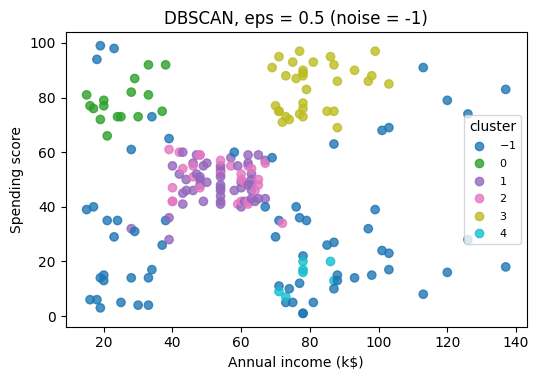

In [14]:
for eps in [0.75, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=6).fit_predict(X)
    mask = labels != -1
    n_found = len(set(labels[mask]))
    line = f"eps={eps}: clusters={n_found}, noise points={int((~mask).sum())}"
    if n_found >= 2:
        line += f", silhouette (clustered only)={silhouette_score(X[mask], labels[mask]):.3f}"
    print(line)

eps_half_labels = DBSCAN(eps=0.5, min_samples=6).fit_predict(X)
print(pd.Series(eps_half_labels).value_counts().sort_index().rename("customers").rename_axis("dbscan label"))

fig, ax = plt.subplots(figsize=(5.5, 3.9))
scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                     c=eps_half_labels, cmap="tab10", alpha=0.8)
ax.set_xlabel("Annual income (k$)")
ax.set_ylabel("Spending score")
ax.set_title("DBSCAN, eps = 0.5 (noise = -1)")
ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

**Result.** At eps = 0.75 DBSCAN finds 1 cluster and 14 noise points; at eps = 0.5 it finds 5 clusters and 66 noise points (about a third of the 200 customers), with a higher silhouette (0.528) measured only on the clustered points.

**Which serves marketing better?** Neither replaces K-means for segmenting the whole customer base. eps = 0.75 gives no segmentation at all (one cloud). eps = 0.5 does expose dense, well-separated cores and a list of unusual customers, but its higher silhouette is partly an artefact of scoring only the 134 points that were easy to cluster. For campaigns that must address every customer, K-means with k = 5 is more actionable; DBSCAN at eps = 0.5 is the better *complement* for finding tight core segments and outliers worth separate treatment.

## Verification checklist

- [x] Features are standardized before clustering, and the elbow and silhouette are both reported (Part A).
- [x] The chosen number of clusters is justified with domain usefulness, not a single score: k = 5 is chosen over the silhouette-best k = 6 (0.427 vs 0.417, a negligible gain) because five segments are easy to name and act on — low income/low spend, low income/high spend, middle, high income/high spend, high income/low spend (a conventional budget, target, and re-engage grid) — and the elbow already flattens there.
- [x] The K-means and DBSCAN results are compared, and the DBSCAN radius is stated (eps = 0.75, then 0.5; `min_samples=6`).
- [x] PCA is fitted on training digits only (`final_model.fit(X_dev, y_dev)`), and its components are judged by downstream accuracy on the official test file.
- [x] `models/digits_pca_logistic.joblib` reloads and predicts the first test digits (cell above).

## Check your understanding

**1. What does PCA optimize when it chooses its first principal component?**
The direction (unit vector) along which the projected data has the *largest variance* — equivalently the line that minimizes the total squared reconstruction error. Later components repeat this under the constraint of being orthogonal to the earlier ones.

**2. Why can standardization change which PCA directions appear most important?**
PCA ranks directions by variance, and variance depends on units. Without standardization a feature measured on a large scale (income in dollars versus age in years) dominates the first component simply because of its scale. Standardizing gives every feature unit variance, so the components reflect correlation structure instead of measurement units.

**3. Why should distances and apparent cluster sizes in a t-SNE or UMAP plot not be interpreted as exact properties of the original high-dimensional data?**
t-SNE and UMAP are nonlinear embeddings that preserve *local neighbourhoods* and deliberately distort global geometry. Gaps between clusters, cluster sizes, and densities depend on hyper-parameters (perplexity, n_neighbors) and the random seed, so only "these points are near each other" is trustworthy — not how far apart groups are or how big they look.